In [30]:
import pandas as pd
df = pd.read_csv("auto_mpg.csv", na_values="?")
df.head()          # first 5 rows
df.shape           # (rows, columns)
df.isna().sum()    # missing values per column

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

In [31]:
df = df[["horsepower", "mpg"]]
df = df.dropna()
print(df.shape)
print(df.isna().sum())

(392, 2)
horsepower    0
mpg           0
dtype: int64


In [32]:
from sklearn.model_selection import train_test_split
x = df[["horsepower"]]
y = df["mpg"]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

model = LinearRegression()
model.fit(x_train, y_train)

train_pred = model.predict(x_train)
test_pred = model.predict(x_test)

train_r2 = r2_score(y_train, train_pred)
test_r2 = r2_score(y_test, test_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

print("Train R2:", train_r2, "Test R2:", test_r2)
print("Train RMSE:", train_rmse, "Test RMSE:", test_rmse)

Train R2: 0.6121193728863614 Test R2: 0.5659681822256185
Train RMSE: 4.947238449244533 Test RMSE: 4.706722545876633


In [34]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

results = []

for degree in [1, 2, 3, 4, 5, 6]:
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree)),   # was degree=3, now uses the loop variable
        ("lr", LinearRegression())
    ])
    # 1. fit the model on x_train, y_train
    # 2. get predictions for x_train and for x_test
    # 3. compute train R², test R², train RMSE, test RMSE
    # 4. results.append({...})

results_df = pd.DataFrame(results)
print(results_df)

Empty DataFrame
Columns: []
Index: []


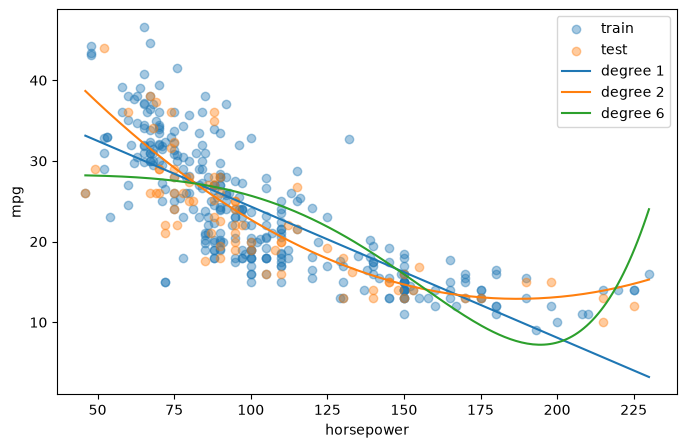

In [35]:
import matplotlib.pyplot as plt

grid = np.linspace(x_train["horsepower"].min(), x_train["horsepower"].max(), 200)
grid_df = pd.DataFrame({"horsepower": grid})   # same column name as training data

plt.figure(figsize=(8, 5))
plt.scatter(x_train, y_train, alpha=0.4, label="train")
plt.scatter(x_test, y_test, alpha=0.4, label="test")

for d in [1, 2, 6]:
    m = Pipeline([
        ("poly", PolynomialFeatures(degree=d)),
        ("lr", LinearRegression())
    ])
    m.fit(x_train, y_train)
    plt.plot(grid, m.predict(grid_df), label=f"degree {d}")

plt.xlabel("horsepower"); plt.ylabel("mpg"); plt.legend()
plt.show()